In [1]:
import os
import shutil
import pandas as pd
from PIL import Image, ImageOps
from sklearn.model_selection import StratifiedShuffleSplit
from PIL import ImageEnhance
import numpy as np
import torch
import torch.nn as nn
from torchvision import models, transforms
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.multioutput import MultiOutputClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import precision_score, recall_score, f1_score
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    accuracy_score, classification_report, confusion_matrix
)
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import confusion_matrix

In [2]:

torch.manual_seed(42)
np.random.seed(42)

In [3]:
P1_IMG_DIR = "/kaggle/input/datasets/sanjeedaafrose/dataset/Phase1-20261125T190005Z-1-001/Phase1"
P2_IMG_DIR = "/kaggle/input/datasets/sanjeedaafrose/dataset/Phase2-20261125T190139Z-1-001/Phase2"
P1_EXCEL   = "/kaggle/input/datasets/sanjeedaafrose/dataset/phase1.xlsx"
P2_EXCEL   = "/kaggle/input/datasets/sanjeedaafrose/dataset/Phase2.xlsx"

In [4]:
OUT_DIR     = "/kaggle/working/merged_dataset"
OUT_IMG_DIR = os.path.join(OUT_DIR, "images")
OUT_EXCEL   = os.path.join(OUT_DIR, "merged_labels.xlsx")

In [5]:
if os.path.exists(OUT_IMG_DIR):
    shutil.rmtree(OUT_IMG_DIR)
os.makedirs(OUT_IMG_DIR, exist_ok=True)

In [6]:
df1 = pd.read_excel(P1_EXCEL).rename(columns={
    "Img Reference": "original_image",
    "ES Reference": "es_code",
    "Status": "status",
})
df1["phase"] = "Phase1"

In [7]:
df2 = pd.read_excel(P2_EXCEL).rename(columns={
    "Photo": "original_image",
    "ES Checkpoint": "es_code",
    "Status": "status",
})
df2["phase"] = "Phase2"

In [8]:
# Standardize compliance classes across both phases
STATUS_MAP = {
    "acceptable": "Acceptable",
    "unacceptable": "Unacceptable",
    "onsite verification required": "Onsite Verification",
    "need onsite verification": "Onsite Verification",
    "onsite verification": "Onsite Verification",
}

In [9]:
def process_phase(df, src_dir, prefix):
    disk_files = {
        f.strip().lower(): f
        for f in os.listdir(src_dir)
        if os.path.isfile(os.path.join(src_dir, f))
    }

    df = df.copy()
    df["orig_clean"] = df["original_image"].astype(str).str.strip()
    df["es_code"] = df["es_code"].astype(str).str.strip().str.upper()
    df["status_raw"] = df["status"].astype(str).str.strip()
    df["status"] = df["status_raw"].str.lower().map(STATUS_MAP)

    unmapped = df[df["status"].isna()]["status_raw"].unique()
    if len(unmapped) > 0:
        raise ValueError(f"Unmapped status values found: {unmapped}")

    df["real_fname"] = df["orig_clean"].str.lower().map(disk_files)
    missing_rows = int(df["real_fname"].isna().sum())
    df = df.dropna(subset=["real_fname"]).copy()

    df["image_name"] = df["real_fname"].apply(
        lambda x: f"{prefix}_{os.path.splitext(x)[0].lower()}.jpg"
    )


    unique_imgs = df[["real_fname", "image_name"]].drop_duplicates()
    for real_f, new_f in unique_imgs.itertuples(index=False):
        shutil.copy2(os.path.join(src_dir, real_f), os.path.join(OUT_IMG_DIR, new_f))

    print(
        f"{prefix.upper()}: copied {len(unique_imgs)} unique images ({len(df)} rows); "
        f"dropped {missing_rows} rows with missing image files."
    )
    return df[["image_name", "es_code", "status", "phase"]]

In [10]:
def process_phase(df, src_dir, prefix):
    # Lookup table for case-insensitive file matching
    disk_files = {f.strip().lower(): f for f in os.listdir(src_dir) if os.path.isfile(os.path.join(src_dir, f))}

    df = df.copy()
    df["es_code"] = df["es_code"].astype(str).str.strip().str.upper()
    df["status"]  = df["status"].astype(str).str.strip().str.lower().map(STATUS_MAP)
    
    # Match existing images and drop rows where file is missing
    df["real_fname"] = df["original_image"].astype(str).str.strip().str.lower().map(disk_files)
    df = df.dropna(subset=["real_fname"]).copy()
    
    # Conflict-free filename
    df["image_name"] = df["real_fname"].apply(lambda x: f"{prefix}_{os.path.splitext(x)[0].lower()}.jpg")

    # Copy files
    for real_f, new_f in df[["real_fname", "image_name"]].drop_duplicates().itertuples(index=False):
        shutil.copy2(os.path.join(src_dir, real_f), os.path.join(OUT_IMG_DIR, new_f))

    return df[["image_name", "es_code", "status", "phase"]]

In [11]:
clean1 = process_phase(df1, P1_IMG_DIR, "p1")
clean2 = process_phase(df2, P2_IMG_DIR, "p2")
merged_df = pd.concat([clean1, clean2], ignore_index=True)

merged_df = merged_df.drop_duplicates(subset=["image_name", "es_code"], keep="first").reset_index(drop=True)

In [12]:
merged_df.to_excel(OUT_EXCEL, index=False)

In [13]:
display(merged_df.tail(10))

,image_name,es_code,status,phase
508,p2_144.jpg,ES94,Onsite Verification,Phase2
509,p2_145.jpg,ES94,Onsite Verification,Phase2
510,p2_145.jpg,ES63,Acceptable,Phase2
511,p2_153.jpg,ES13,Onsite Verification,Phase2
512,p2_153.jpg,ES24,Unacceptable,Phase2
513,p2_154.jpg,ES27,Unacceptable,Phase2
514,p2_155.jpg,ES27,Onsite Verification,Phase2
515,p2_156.jpg,ES27,Unacceptable,Phase2
516,p2_157.jpg,ES27,Onsite Verification,Phase2
517,p2_158.jpg,ES66,Unacceptable,Phase2


In [14]:
print(merged_df["status"].value_counts().to_string())

status
Unacceptable           313
Acceptable             147
Onsite Verification     58


In [15]:
print("Images in merged folder :", len(os.listdir(OUT_IMG_DIR)))
print("Unique images in Excel  :", merged_df["image_name"].nunique())
print("Total rows in Excel     :", len(merged_df))
print("Unique ES codes         :", merged_df["es_code"].nunique())
print("\nUnified Class Counts (Full Dataset):")

Images in merged folder : 245
Unique images in Excel  : 245
Total rows in Excel     : 518
Unique ES codes         : 50

Unified Class Counts (Full Dataset):


In [16]:
merged_df = pd.read_excel(OUT_EXCEL)
es_only = (
    merged_df["es_code"]
    .value_counts()
    .reset_index()
    .rename(columns={"es_code": "ES", "count": "Total"})
)

display(es_only)

,ES,Total
0,ES27,71
1,ES15,67
2,ES6,33
3,ES10,30
4,ES24,29
5,ES2,27
6,ES5,23
7,ES13,23
8,ES7,19
9,ES38,15


In [17]:
NEW_DIR     = "/kaggle/working/dataset_Final"
NEW_IMG_DIR = os.path.join(NEW_DIR, "images")
NEW_EXCEL   = os.path.join(NEW_DIR, "labels_ES_FINAL.xlsx")

In [18]:
if os.path.exists(NEW_IMG_DIR):
    shutil.rmtree(NEW_IMG_DIR)
os.makedirs(NEW_IMG_DIR, exist_ok=True)

In [19]:
def load_matched(excel_path, img_dir, img_col, es_col):
    disk_map = {
        f.strip().lower(): f
        for f in os.listdir(img_dir)
        if os.path.isfile(os.path.join(img_dir, f))
    }
    df = pd.read_excel(excel_path)
    df["Image"] = df[img_col].astype(str).str.strip().str.lower().map(disk_map)
    df = df.dropna(subset=["Image"]).copy()  # Keep exact original filename on disk
    df["ES"] = df[es_col].astype(str).str.strip().str.upper()
    df["Status"] = df["Status"].astype(str).str.strip().str.lower().map(STATUS_MAP)
    df["src_dir"] = img_dir
    return df[["Image", "ES", "Status", "src_dir"]]

In [20]:
df_all = pd.concat([
    load_matched(P1_EXCEL, P1_IMG_DIR, "Img Reference", "ES Reference"),
    load_matched(P2_EXCEL, P2_IMG_DIR, "Photo", "ES Checkpoint"),
], ignore_index=True)

In [21]:
# Keep only ES codes that have MORE THAN 5 unique images (> 5)
es_img_counts = df_all.groupby("ES")["Image"].nunique()
valid_es = es_img_counts[es_img_counts > 5].index
filtered_df = df_all[df_all["ES"].isin(valid_es)].copy()

In [22]:
# Copy exact original image files untouched (no renaming or modification)
unique_imgs = filtered_df[["Image", "src_dir"]].drop_duplicates()
for fname, sdir in unique_imgs.itertuples(index=False):
    shutil.copy2(os.path.join(sdir, fname), os.path.join(NEW_IMG_DIR, fname))

In [23]:
out_df = filtered_df[["Image", "ES", "Status"]].reset_index(drop=True)
out_df.to_excel(NEW_EXCEL, index=False)

In [24]:
print("Selected ES codes  :", out_df["ES"].nunique())
print("Images in folder   :", len(os.listdir(NEW_IMG_DIR)))
print("Total Excel rows   :", len(out_df))
display(out_df.head(10))

Selected ES codes  : 23
Images in folder   : 221
Total Excel rows   : 463


,Image,ES,Status
0,0001.jpg,ES2,Acceptable
1,0001.jpg,ES15,Acceptable
2,0001.jpg,ES27,Onsite Verification
3,0002.JPG,ES2,Acceptable
4,0002.JPG,ES13,Onsite Verification
5,0002.JPG,ES15,Acceptable
6,0002.JPG,ES27,Onsite Verification
7,0003.jpg,ES2,Acceptable
8,0003.jpg,ES15,Acceptable
9,0003.jpg,ES39,Acceptable


In [25]:
# Preprocess Images (EXIF Fix, RGB, Resize 224x224)
PREP_DIR     = os.path.join(NEW_DIR, "preprocessed")
PREP_IMG_DIR = os.path.join(PREP_DIR, "images_224")
os.makedirs(PREP_IMG_DIR, exist_ok=True)

IMG_SIZE = (224, 224)
for fname in out_df["Image"].unique():
    with Image.open(os.path.join(NEW_IMG_DIR, fname)) as img:
        img = ImageOps.exif_transpose(img).convert("RGB")
        img = img.resize(IMG_SIZE, Image.Resampling.BILINEAR)
        img.save(os.path.join(PREP_IMG_DIR, fname), quality=95)

print(f"Saved {out_df['Image'].nunique()} preprocessed {IMG_SIZE} RGB images.")

Saved 221 preprocessed (224, 224) RGB images.


In [26]:
# Encode Status IDs, ES IDs 

STATUS_TO_ID = {"Acceptable": 0, "Unacceptable": 1, "Onsite Verification": 2}
ES_LIST      = sorted(out_df["ES"].unique())
ES_TO_ID     = {es: i for i, es in enumerate(ES_LIST)}

out_df["status_id"] = out_df["Status"].map(STATUS_TO_ID)
out_df["es_id"]     = out_df["ES"].map(ES_TO_ID)

es_multilabel = (
    pd.crosstab(out_df["Image"], out_df["ES"])
    .reindex(columns=ES_LIST, fill_value=0)
    .clip(upper=1)
    .reset_index()
)
prio_map = {"Unacceptable": 0, "Onsite Verification": 1, "Acceptable": 2}
img_worst_status = (
    out_df.assign(_p=out_df["Status"].map(prio_map))
    .sort_values("_p")
    .drop_duplicates("Image")[["Image", "Status"]]
    .rename(columns={"Status": "img_status"})
)
es_multilabel = es_multilabel.merge(img_worst_status, on="Image", how="left")

In [27]:
# Spliting 80/20
splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
tr_idx, te_idx = next(splitter.split(es_multilabel, es_multilabel["img_status"]))

train_imgs = set(es_multilabel.iloc[tr_idx]["Image"])
test_imgs  = set(es_multilabel.iloc[te_idx]["Image"])

train_es_df    = es_multilabel[es_multilabel["Image"].isin(train_imgs)].reset_index(drop=True)
test_es_df     = es_multilabel[es_multilabel["Image"].isin(test_imgs)].reset_index(drop=True)
train_pairs_df = out_df[out_df["Image"].isin(train_imgs)].reset_index(drop=True)
test_pairs_df  = out_df[out_df["Image"].isin(test_imgs)].reset_index(drop=True)

In [28]:
train_es_df.to_csv(os.path.join(PREP_DIR, "train_es_multilabel.csv"), index=False)
test_es_df.to_csv(os.path.join(PREP_DIR, "test_es_multilabel.csv"), index=False)
train_pairs_df.to_csv(os.path.join(PREP_DIR, "train_pairs.csv"), index=False)
test_pairs_df.to_csv(os.path.join(PREP_DIR, "test_pairs.csv"), index=False)

print(f"Train: {len(train_es_df)} images ({len(train_pairs_df)} rows) | Test: {len(test_es_df)} images ({len(test_pairs_df)} rows)")
print("ES codes in Train / Test:", int((train_es_df[ES_LIST].sum() > 0).sum()), "/", int((test_es_df[ES_LIST].sum() > 0).sum()))

Train: 176 images (369 rows) | Test: 45 images (94 rows)
ES codes in Train / Test: 23 / 23


In [29]:
# Data Augmentation

TRAIN_AUG_DIR = os.path.join(PREP_DIR, "train_aug_images_224")
if os.path.exists(TRAIN_AUG_DIR):
    shutil.rmtree(TRAIN_AUG_DIR)
os.makedirs(TRAIN_AUG_DIR, exist_ok=True)

aug_es_rows = []
aug_pair_rows = []

for idx, row in train_es_df.iterrows():
    fname = row["Image"]
    base_name, ext = os.path.splitext(fname)
    img_pairs = train_pairs_df[train_pairs_df["Image"] == fname]

    with Image.open(os.path.join(PREP_IMG_DIR, fname)) as img:
        # 1. Original train image
        orig_name = fname
        img.save(os.path.join(TRAIN_AUG_DIR, orig_name), quality=95)

        # 2. Augmented 1: Horizontal flip + mild brightness boost
        aug1_name = f"aug1_{base_name}{ext}"
        aug1 = ImageEnhance.Brightness(ImageOps.mirror(img)).enhance(1.12)
        aug1.save(os.path.join(TRAIN_AUG_DIR, aug1_name), quality=95)

        # 3. Augmented 2: Mild rotation (+/- 8 deg) + mild contrast boost
        aug2_name = f"aug2_{base_name}{ext}"
        angle = 8 if idx % 2 == 0 else -8
        aug2 = ImageEnhance.Contrast(img.rotate(angle, resample=Image.Resampling.BILINEAR)).enhance(1.12)
        aug2.save(os.path.join(TRAIN_AUG_DIR, aug2_name), quality=95)

    # Copy matching ES & Status labels for the 3 train versions only
    for new_fname in [orig_name, aug1_name, aug2_name]:
        new_es_row = row.copy()
        new_es_row["Image"] = new_fname
        aug_es_rows.append(new_es_row)

        new_pairs = img_pairs.copy()
        new_pairs["Image"] = new_fname
        aug_pair_rows.append(new_pairs)

train_es_aug_df    = pd.DataFrame(aug_es_rows).reset_index(drop=True)
train_pairs_aug_df = pd.concat(aug_pair_rows, ignore_index=True)


train_es_aug_df.to_csv(os.path.join(PREP_DIR, "train_es_multilabel_aug.csv"), index=False)
train_pairs_aug_df.to_csv(os.path.join(PREP_DIR, "train_pairs_aug.csv"), index=False)

print(f"Train before augmentation : {len(train_es_df)} images ({len(train_pairs_df)} rows)")
print(f"Train after augmentation  : {len(train_es_aug_df)} images ({len(train_pairs_aug_df)} rows)")
print(f"Test  : {len(test_es_df)} images ({len(test_pairs_df)} rows)")
print("\nAugmented Train Status counts:\n", train_pairs_aug_df["Status"].value_counts().to_string())

Train before augmentation : 176 images (369 rows)
Train after augmentation  : 528 images (1107 rows)
Test  : 45 images (94 rows)

Augmented Train Status counts:
 Status
Unacceptable           648
Acceptable             330
Onsite Verification    129


In [30]:
from torchvision import transforms
img_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [31]:
#define the tensors
def build_unified_tensors(es_df, pairs_df, img_folder):
    imgs = torch.stack([
        img_transform(Image.open(os.path.join(img_folder, f)).convert("RGB"))
        for f in es_df["Image"]
    ])
    y_es = torch.tensor(es_df[ES_LIST].values, dtype=torch.float32)

    # -100 marks "Not Applicable" ES slots so Status loss ignores them automatically
    y_st_np = np.full((len(es_df), len(ES_LIST)), -100, dtype=np.int64)
    img_to_idx = {img: i for i, img in enumerate(es_df["Image"])}
    for row in pairs_df.itertuples():
        y_st_np[img_to_idx[row.Image], row.es_id] = row.status_id

    y_st = torch.tensor(y_st_np, dtype=torch.long)
    return imgs, y_es, y_st

X_tr_img, Y_tr_es, Y_tr_st = build_unified_tensors(train_es_aug_df, train_pairs_aug_df, TRAIN_AUG_DIR)
X_te_img, Y_te_es, Y_te_st = build_unified_tensors(test_es_df, test_pairs_df, PREP_IMG_DIR)

train_loader = DataLoader(TensorDataset(X_tr_img, Y_tr_es, Y_tr_st), batch_size=32, shuffle=True)

In [32]:
#model Architecture
class UnifiedAuditNet(nn.Module):
    def __init__(self, num_es, num_status=3, emb_dim=64):
        super().__init__()
        base = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        # Freeze early layers; fine-tune deeper semantic layers (layer3, layer4)
        for name, param in base.named_parameters():
            if not (name.startswith("layer3") or name.startswith("layer4")):
                param.requires_grad = False
        self.backbone = nn.Sequential(*list(base.children())[:-1])

        # Branch 1: Predict applicable ES numbers from image features
        self.es_head = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(512, num_es),
        )

        # Branch 2: Predict 3-class Status per ES using Image features + ES embedding
        self.es_emb = nn.Embedding(num_es, emb_dim)
        self.status_head = nn.Sequential(
            nn.Linear(512 + emb_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_status),
        )
        self.num_es = num_es

    def forward(self, x):
        feat = self.backbone(x).flatten(1)                                # (B, 512)
        es_logits = self.es_head(feat)                                    # (B, 23)

        es_ids = torch.arange(self.num_es, device=x.device)
        emb = self.es_emb(es_ids).unsqueeze(0).expand(x.size(0), -1, -1)  # (B, 23, 64)
        feat_exp = feat.unsqueeze(1).expand(-1, self.num_es, -1)          # (B, 23, 512)
        status_logits = self.status_head(torch.cat([feat_exp, emb], dim=-1))  # (B, 23, 3)
        return es_logits, status_logits

In [33]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [34]:
model = UnifiedAuditNet(num_es=len(ES_LIST)).to(device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 159MB/s]


In [35]:
# Loss & Optimizer
pos_counts = Y_tr_es.sum(dim=0)
neg_counts = len(Y_tr_es) - pos_counts
pos_weight = torch.sqrt(neg_counts / pos_counts).to(device)
bce_loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

valid_st = Y_tr_st[Y_tr_st != -100].numpy()
st_counts = np.bincount(valid_st, minlength=3)
st_weights = torch.tensor(len(valid_st) / (3.0 * st_counts), dtype=torch.float32).to(device)
ce_loss_fn = nn.CrossEntropyLoss(weight=st_weights, ignore_index=-100)

optimizer = torch.optim.AdamW([
    {"params": [p for p in model.backbone.parameters() if p.requires_grad], "lr": 1e-4},
    {"params": list(model.es_head.parameters()) + list(model.es_emb.parameters()) + list(model.status_head.parameters()), "lr": 1e-3},
], weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)

In [36]:
#Training Loop
EPOCHS = 40
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    for bx, by_es, by_st in train_loader:
        bx, by_es, by_st = bx.to(device), by_es.to(device), by_st.to(device)
        optimizer.zero_grad()

        es_logits, st_logits = model(bx)
        loss_es = bce_loss_fn(es_logits, by_es)
        loss_st = ce_loss_fn(st_logits.reshape(-1, 3), by_st.reshape(-1))
        loss = loss_es + loss_st

        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(bx)
        
    scheduler.step()
    
 
    current_lr = scheduler.get_last_lr()[0]
    print(f"Epoch {epoch:3d}/{EPOCHS} | Loss: {total_loss / len(X_tr_img):.4f} | LR: {current_lr:.6f}")

Epoch   1/40 | Loss: 1.4022 | LR: 0.000100
Epoch   2/40 | Loss: 0.6635 | LR: 0.000099
Epoch   3/40 | Loss: 0.3902 | LR: 0.000099
Epoch   4/40 | Loss: 0.2734 | LR: 0.000098
Epoch   5/40 | Loss: 0.2196 | LR: 0.000096
Epoch   6/40 | Loss: 0.1684 | LR: 0.000095
Epoch   7/40 | Loss: 0.1372 | LR: 0.000093
Epoch   8/40 | Loss: 0.1090 | LR: 0.000090
Epoch   9/40 | Loss: 0.0867 | LR: 0.000088
Epoch  10/40 | Loss: 0.0698 | LR: 0.000085
Epoch  11/40 | Loss: 0.0608 | LR: 0.000082
Epoch  12/40 | Loss: 0.0484 | LR: 0.000079
Epoch  13/40 | Loss: 0.0468 | LR: 0.000076
Epoch  14/40 | Loss: 0.0370 | LR: 0.000073
Epoch  15/40 | Loss: 0.0360 | LR: 0.000069
Epoch  16/40 | Loss: 0.0318 | LR: 0.000065
Epoch  17/40 | Loss: 0.0287 | LR: 0.000062
Epoch  18/40 | Loss: 0.0256 | LR: 0.000058
Epoch  19/40 | Loss: 0.0247 | LR: 0.000054
Epoch  20/40 | Loss: 0.0246 | LR: 0.000050
Epoch  21/40 | Loss: 0.0217 | LR: 0.000046
Epoch  22/40 | Loss: 0.0210 | LR: 0.000042
Epoch  23/40 | Loss: 0.0227 | LR: 0.000038
Epoch  24/4

In [37]:
#evaluation
model.eval()
with torch.no_grad():
    te_es_logits, te_st_logits = model(X_te_img.to(device))
    te_es_probs = torch.sigmoid(te_es_logits).cpu().numpy()
    te_st_preds = te_st_logits.argmax(dim=-1).cpu().numpy()

# Threshold 0.55 for ES detection (+ top-1 fallback if none >= threshold)
Y_te_es_np = Y_te_es.numpy().astype(int)
Y_te_es_pred = (te_es_probs >= 0.55).astype(int)
for i in range(len(Y_te_es_pred)):
    if Y_te_es_pred[i].sum() == 0:
        Y_te_es_pred[i, np.argmax(te_es_probs[i])] = 1

In [38]:
tp, fp, fn = 0, 0, 0
for i in range(len(Y_te_es_np)):
    true_pairs = {(j, int(Y_te_st[i, j])) for j in np.where(Y_te_es_np[i] == 1)[0]}
    pred_pairs = {(j, int(te_st_preds[i, j])) for j in np.where(Y_te_es_pred[i] == 1)[0]}
    
    tp += len(true_pairs & pred_pairs)
    fp += len(pred_pairs - true_pairs)
    fn += len(true_pairs - pred_pairs)

# Standard Multi-Label Audit Accuracy (Jaccard Match Ratio: Intersection over Union)
accuracy  = tp / (tp + fp + fn) if (tp + fp + fn) > 0 else 0.0
precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
recall    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
f1_score  = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0.0


print(f"Total True (ES, Status) Pairs    : {tp + fn}")
print(f"Correctly Predicted Pairs (TP)   : {tp}")
print(f"Audit Precision                  : {precision:.4f}")
print(f"Audit Recall                     : {recall:.4f}")
print(f"Audit Overall F1-Score           : {f1_score:.4f}")

Total True (ES, Status) Pairs    : 93
Correctly Predicted Pairs (TP)   : 34
Audit Precision                  : 0.5000
Audit Recall                     : 0.3656
Audit Overall F1-Score           : 0.4224


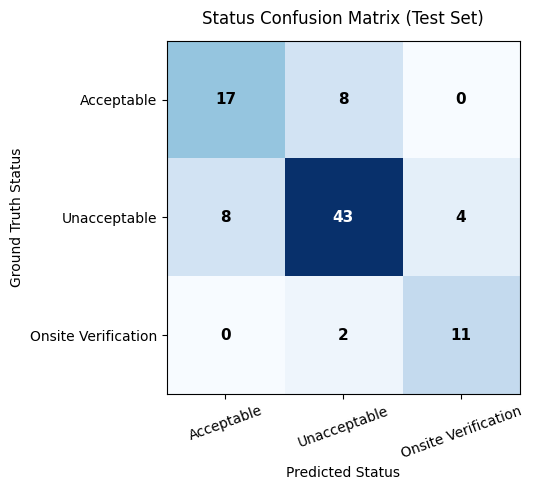

In [39]:
CLASS_NAMES = ["Acceptable", "Unacceptable", "Onsite Verification"]
valid_mask = Y_te_st.numpy() != -100
y_true_st  = Y_te_st.numpy()[valid_mask]
y_pred_st  = te_st_preds[valid_mask]

cm = confusion_matrix(y_true_st, y_pred_st)


plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.title("Status Confusion Matrix (Test Set)", fontsize=12, pad=12)
plt.xticks(range(3), CLASS_NAMES, rotation=20)
plt.yticks(range(3), CLASS_NAMES)
plt.xlabel("Predicted Status", fontsize=10)
plt.ylabel("Ground Truth Status", fontsize=10)

# Add exact counts inside each cell
for r in range(3):
    for c in range(3):
        color = "white" if cm[r, c] > cm.max() / 2 else "black"
        plt.text(c, r, str(cm[r, c]), ha="center", va="center", fontsize=11, fontweight="bold", color=color)

plt.tight_layout()
plt.show()